In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import argparse
import os

import torch

sns.set_theme()

c:\Users\seanc\anaconda3\envs\deepphysics\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [20]:
VERSION = 2
num_channels = VERSION + 2
data = np.load(f'data/GT_test_{VERSION}D.npy')
print(data.shape)

(21, 512, 512, 1, 200)


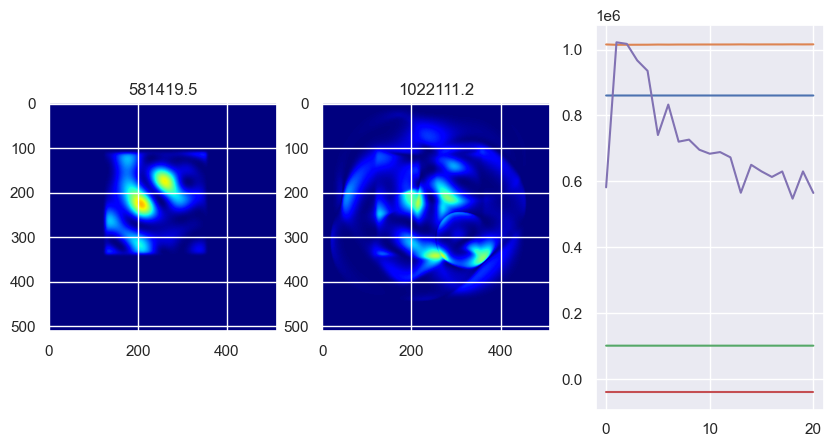

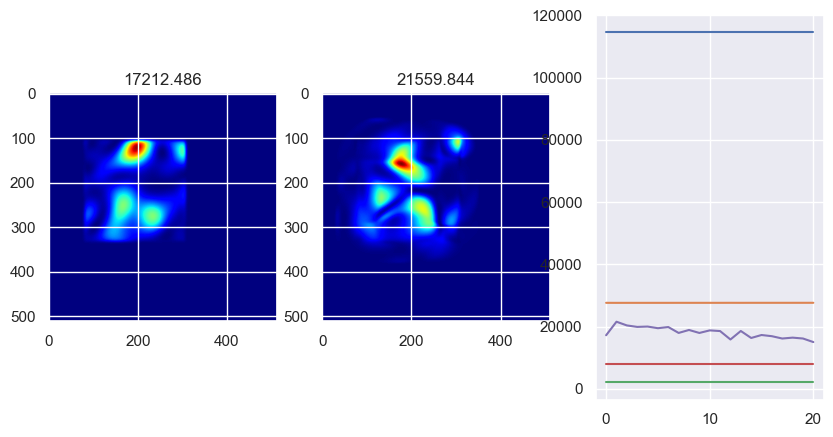

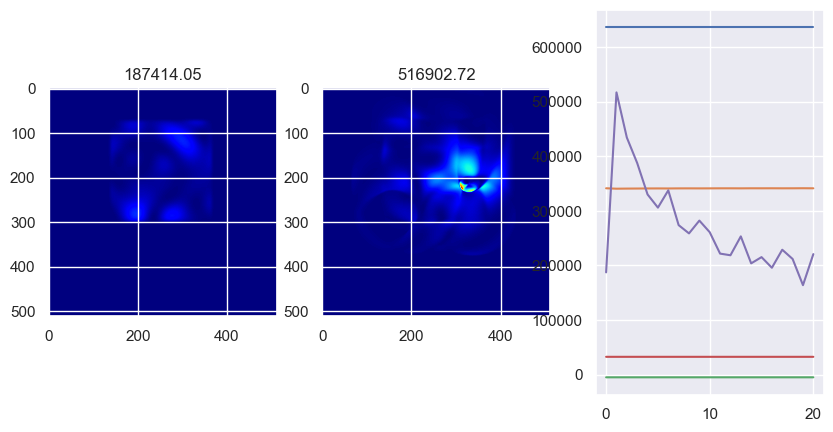

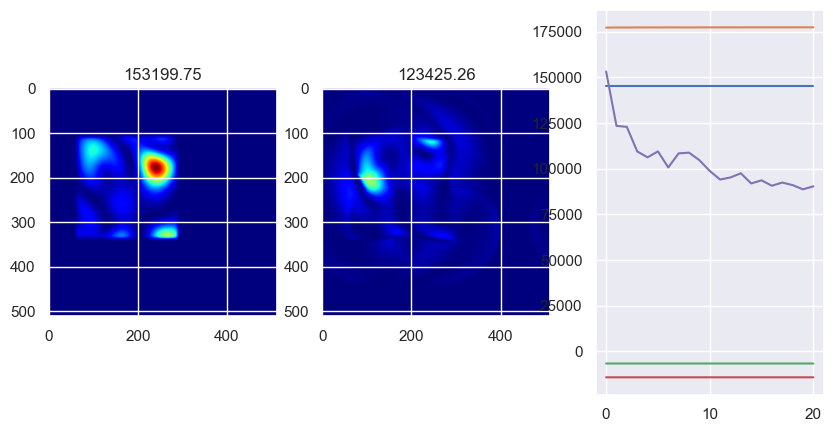

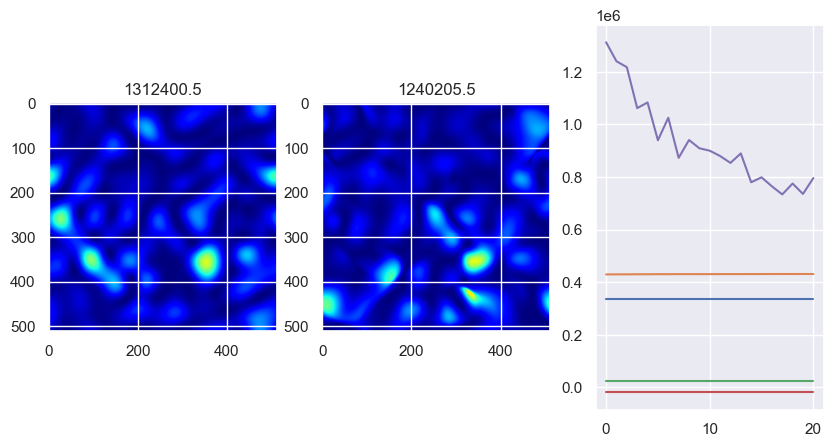

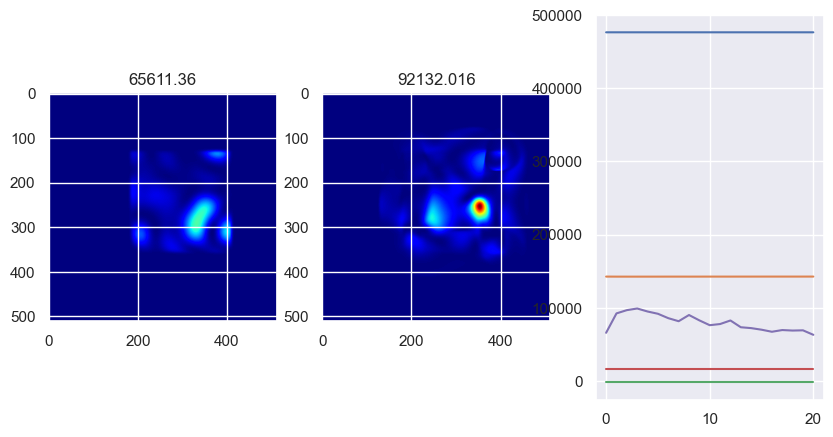

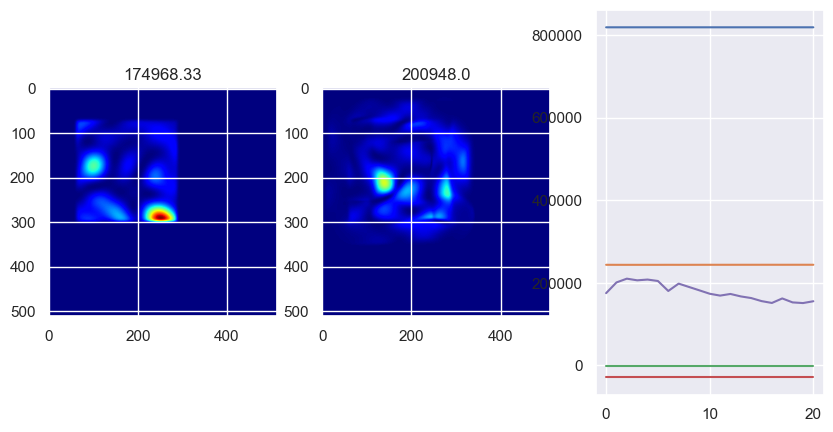

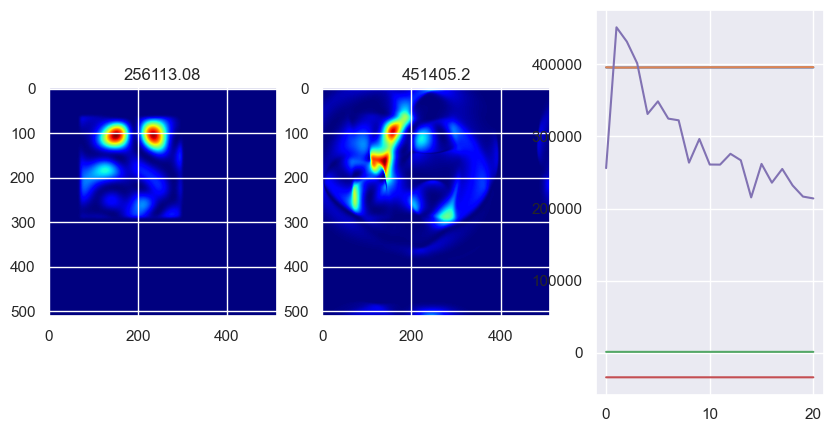

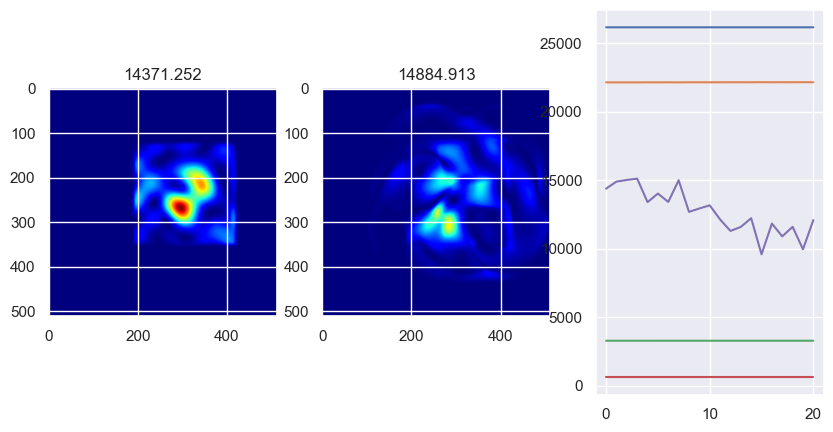

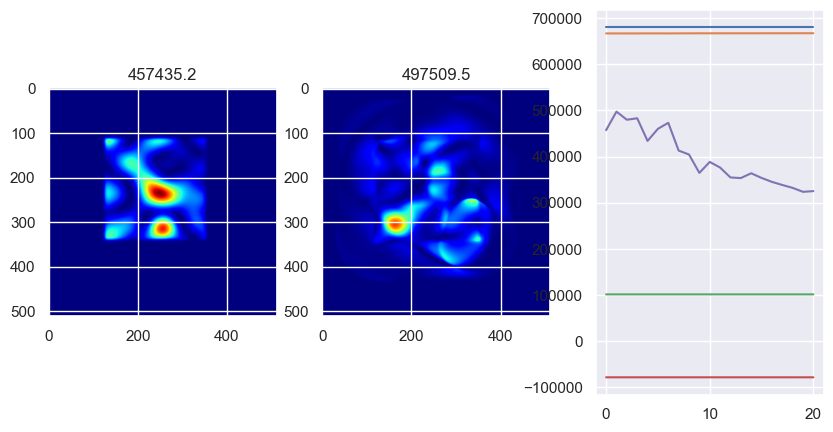

In [18]:
energy_curves = []
for i in range(10): #data.shape[-1] // num_channels):
    solution = data[..., i * num_channels: (i + 1) * num_channels]
    # plt.imshow(solution[0, :, :, 0, 0], cmap='jet')
    # plt.colorbar()
    # plt.show()

    total_density = np.sum(solution[..., 0], axis = (1, 2, 3))
    squared_velocity = np.sum(solution[..., 1:-1] ** 2, axis = -1)
    total_pressure = np.sum(solution[..., -1], axis = (1, 2, 3))
    total_mx = np.sum(solution[..., 0] * solution[..., 1], axis=(1, 2, 3))
    total_my = np.sum(solution[..., 0] * solution[..., 2], axis=(1, 2, 3))
    total_kinetic = np.sum(0.5 * solution[..., 0] * (squared_velocity), axis = (1, 2, 3))
    total_energy = total_kinetic + 1.5 * total_pressure
    
    energy_curves.append(total_energy)

    kinetic = 0.5 * solution[..., 0] * (squared_velocity)
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 5))
    ax1.imshow(kinetic[0, :, :, 0], cmap='jet', vmin=kinetic.min(), vmax=kinetic.max())
    ax1.set_title(str(kinetic[0].sum()))
    ax2.imshow(kinetic[1, :, :, 0], cmap='jet', vmin=kinetic.min(), vmax=kinetic.max())
    ax2.set_title(str(kinetic[1].sum()))
    ax3.plot(total_density)
    ax3.plot(total_pressure)
    ax3.plot(total_mx)
    ax3.plot(total_my)
    ax3.plot(total_kinetic)
    plt.show()

energy_curves = np.array(energy_curves)

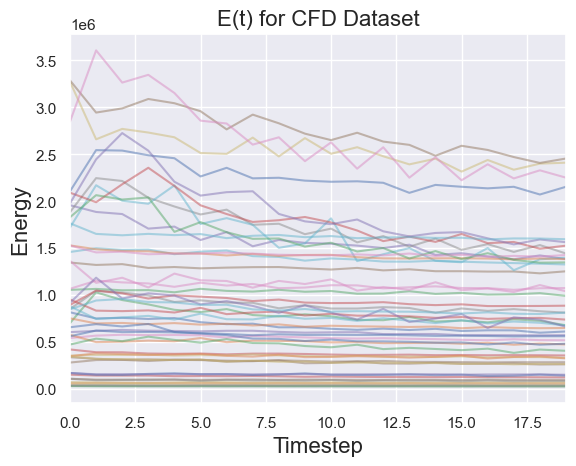

In [5]:
for i in range(len(energy_curves)):
    plt.plot(energy_curves[i], alpha=0.5)
    # plt.plot(energy_curves[i] / energy_curves[i, 0], color='tab:blue', alpha=0.5)

plt.title('E(t) for CFD Dataset', fontsize=16)
plt.xlabel('Timestep', fontsize=16)
plt.ylabel('Energy', fontsize=16)

plt.xlim(0, 19)

# plt.savefig('compressible_energy_difference.png')

plt.show()

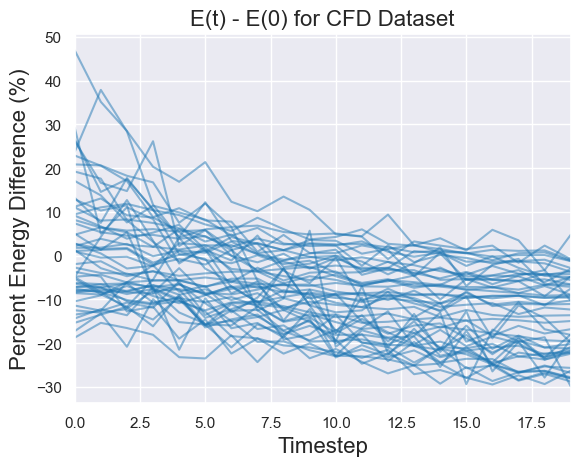

In [6]:
differences = (energy_curves[:, 1:] - energy_curves[:, :1]) / energy_curves[:, 0:1] * 100

for i in range(len(energy_curves)):
    plt.plot(differences[i], color='tab:blue', alpha=0.5)

plt.title('E(t) - E(0) for CFD Dataset', fontsize=16)
plt.xlabel('Timestep', fontsize=16)
plt.ylabel('Percent Energy Difference (%)', fontsize=16)

plt.xlim(0, 19)

plt.savefig('compressible_energy_difference.png')

plt.show()

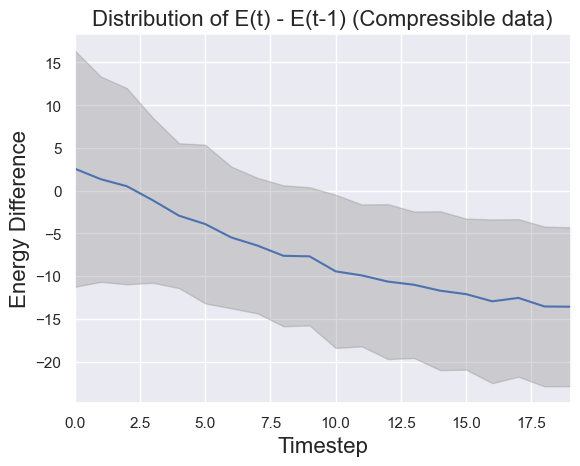

In [ ]:
plt.plot(np.arange(differences.shape[1]), differences.mean(axis=0))
plt.fill_between(np.arange(differences.shape[1]),
                 differences.mean(axis=0) - differences.std(axis=0),
                 differences.mean(axis=0) + differences.std(axis=0), color='gray', alpha=0.3)

plt.title('Distribution of E(t) - E(t-1) (Compressible data)', fontsize=16)
plt.xlabel('Timestep', fontsize=16)
plt.ylabel('Energy Difference', fontsize=16)

plt.xlim(0, 19)

# plt.savefig('compressible_energy_difference.png')

plt.show()

In [ ]:
energies = []
for i in range(data.shape[-1] // num_channels):
    solution = data[..., i * num_channels: (i + 1) * num_channels]

    density = solution[..., 0]
    squared_velocity = np.sum(solution[..., 1:-1] ** 2, axis = -1)
    pressure = solution[..., -1]
    kinetic = 0.5 * solution[..., 0] * (squared_velocity)
    energy = pressure * 1.5 + kinetic
    
    energy = energy - energy.mean()

    energies.append(energy)

energies = np.array(energies)

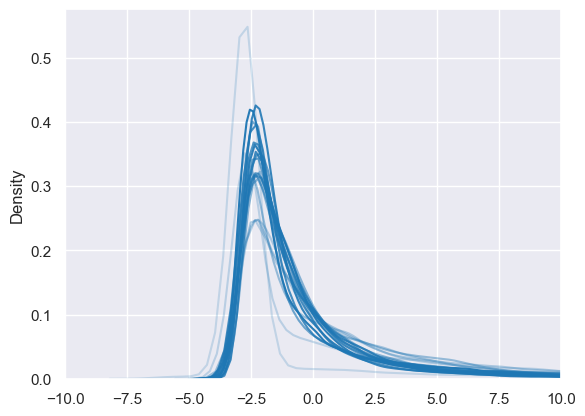

In [ ]:
eg = energies[0]

for i in range(len(eg)):
    sns.kdeplot(eg[i].flatten(), color='tab:blue', alpha=0.2 + i * (0.8 / len(eg)))

plt.xlim(-10, 10)
plt.show()

In [22]:
def pde_CFD1d_full_solution(y, gamma=1.4):
    y = torch.Tensor(y).cpu()
    x = GRID
    
    h2 = y[..., -3].squeeze()  # rho
    ux2 = y[..., -2].squeeze()  # vx
    p2 = y[..., -1].squeeze()  # p
    E2 = p2/(gamma - 1.) + 0.5 * h2 * (ux2**2)
    E2 = E2.squeeze()
    Fx = ux2 * (E2 + p2)
    Fx = Fx.squeeze()
    
    # non conservative form

    _, hu_x = torch.gradient(h2 * ux2)
    
    ux_t, ux_x = torch.gradient(ux2)
    _, p_x = torch.gradient(p2)

    _, Fx_x = torch.gradient(Fx)
    
    h_t, _ = torch.gradient(h2)
    E_t, _ = torch.gradient(E2)

    eq1 = h_t + hu_x
    eq2 = h2 * (ux_t + ux2 * ux_x) - p_x
    eq3 = E_t + Fx_x

    residuals = (torch.mean(torch.abs(eq1)),
                 torch.mean(torch.abs(eq2)),
                 torch.mean(torch.abs(eq3)))
    return residuals

In [29]:
def pde_CFD2d_full_solution(y, gamma=1.4):
    y = torch.Tensor(y).cpu()
    x = GRID
    
    h2 = y[..., -4].squeeze()  # rho
    ux2 = y[..., -3].squeeze()  # vx
    uy2 = y[..., -2].squeeze()  # vy
    p2 = y[..., -1].squeeze()  # p
    E2 = p2/(gamma - 1.) + 0.5 * h2 * (ux2**2 + uy2**2)
    E2 = E2.squeeze()
    Fx = ux2 * (E2 + p2)
    Fx = Fx.squeeze()
    Fy = uy2 * (E2 + p2)
    Fy = Fy.squeeze()

    # non conservative form

    _, hu_x, _ = torch.gradient(h2 * ux2)
    _, _, hu_y = torch.gradient(h2 * uy2)

    ux_t, ux_x, ux_y = torch.gradient(ux2)
    uy_t, uy_x, uy_y = torch.gradient(uy2)
    _, p_x, p_y = torch.gradient(p2)

    _, Fx_x, _ = torch.gradient(Fx)
    _, _, Fy_y = torch.gradient(Fy)
    
    h_t, _, _ = torch.gradient(h2)
    E_t, _, _ = torch.gradient(E2)

    eq1 = h_t + hu_x + hu_y
    eq2 = h2 * (ux_t + ux2 * ux_x + uy2 * ux_y) - p_x
    eq3 = h2 * (uy_t + ux2 * uy_x + uy2 * uy_y) - p_y
    eq4 = E_t + Fx_x + Fy_y

    residuals = (torch.mean(torch.abs(eq1), dim=(1, 2)),
                 torch.mean(torch.abs(eq2), dim=(1, 2)),
                 torch.mean(torch.abs(eq3), dim=(1, 2)),
                 torch.mean(torch.abs(eq4), dim=(1, 2)))
    return residuals


In [24]:
def pde_CFD3d_full_solution(y, gamma=1.4):
    y = torch.Tensor(y).cpu()
    x = GRID
    
    h2 = y[..., 0].squeeze()  # rho
    ux2 = y[..., 1].squeeze()  # vx
    uy2 = y[..., 2].squeeze()  # vy
    uz2 = y[..., 3].squeeze()  # vz
    p2 = y[..., 4].squeeze()  # p
    E2 = p2/(gamma - 1.) + 0.5 * h2 * (ux2**2 + uy2**2 + uz2**2)
    E2 = E2.squeeze()
    Fx = ux2 * (E2 + p2)
    Fx = Fx.squeeze()
    Fy = uy2 * (E2 + p2)
    Fy = Fy.squeeze()
    Fz = uz2 * (E2 + p2)
    Fz = Fz.squeeze()

    # non conservative form
    _, hu_x, _, _ = torch.gradient(h2 * ux2)
    _, _, hu_y, _ = torch.gradient(h2 * uy2)
    _, _, _, hu_z = torch.gradient(h2 * uz2)

    ux_t, ux_x, ux_y, ux_z = torch.gradient(ux2)
    uy_t, uy_x, uy_y, uy_z = torch.gradient(uy2)
    uz_t, uz_x, uz_y, uz_z = torch.gradient(uz2)
    _, p_x, p_y, p_z = torch.gradient(p2)

    _, Fx_x, _, _ = torch.gradient(Fx)
    _, _, Fy_y, _ = torch.gradient(Fy)
    _, _, _, Fz_z = torch.gradient(Fz)
    
    h_t, _, _, _ = torch.gradient(h2)
    E_t, _, _, _ = torch.gradient(E2)

    eq1 = h_t + hu_x + hu_y + hu_z
    eq2 = h2 * (ux_t + ux2 * ux_x + uy2 * ux_y + uz2 * ux_z) - p_x
    eq3 = h2 * (uy_t + ux2 * uy_x + uy2 * uy_y + uz2 * uy_z) - p_y
    eq4 = h2 * (uz_t + ux2 * uz_x + uy2 * uz_y + uz2 * uz_z) - p_z
    eq5 = E_t + Fx_x + Fy_y + Fz_z

    residuals = (torch.mean(torch.abs(eq1)),
                 torch.mean(torch.abs(eq2)),
                 torch.mean(torch.abs(eq3)),
                 torch.mean(torch.abs(eq4)),
                 torch.mean(torch.abs(eq5)))
    return residuals


In [30]:
from source.losses.navier_stokes_loss import *

x = np.linspace(0, 2 * np.pi, num=data.shape[1])
y = np.linspace(0, 2 * np.pi, num=data.shape[2])
z = np.linspace(0, 2 * np.pi, num=data.shape[3])
X, Y, Z = np.meshgrid(x, y, z)
GRID = np.stack((X, Y, Z), axis=-1)

def loss_full_solution(y):
    if VERSION == 1:
        return pde_CFD1d_full_solution(y)
    elif VERSION == 2:
        return pde_CFD2d_full_solution(y)
    elif VERSION == 3:
        return pde_CFD3d_full_solution(y)
    else:
        raise ValueError('Version must be 1, 2, or 3')
    

In [32]:
losses = []
for i in range(data.shape[-1] // num_channels):
    solution = data[..., i * num_channels: (i + 1) * num_channels]
    losses.append([res.cpu().numpy() for res in loss_full_solution(solution)])
        
losses = np.array(losses)
print(losses.mean(axis=0))
print(losses.std(axis=0))

(50, 4, 21)
[[0.11364377 0.08031362 0.09199489 0.09990607 0.10375594 0.10484099
  0.10545894 0.10440989 0.10303605 0.10088073 0.10035703 0.09685154
  0.09576266 0.09405658 0.09211387 0.09067478 0.08870715 0.087102
  0.08599376 0.08481625 0.108994  ]
 [1.2239534  0.6318634  0.66132164 0.6592943  0.6312237  0.62916994
  0.58719754 0.5786801  0.5555104  0.55241996 0.5060299  0.5266062
  0.49312887 0.5042076  0.4719975  0.47558102 0.45098677 0.46334258
  0.43974075 0.44114098 0.8565757 ]
 [1.239964   0.6336333  0.6777831  0.6532726  0.6518647  0.6242395
  0.5998539  0.5843538  0.5610182  0.55843073 0.51598686 0.5335767
  0.50053716 0.500985   0.48147702 0.48318955 0.4609317  0.4752115
  0.4430865  0.45129326 0.8600148 ]
 [2.0362475  1.1714779  1.2170862  1.192678   1.151091   1.1052967
  1.0394875  0.99580264 0.9396045  0.9098835  0.8637553  0.851698
  0.7864288  0.77918035 0.73008966 0.7353966  0.6821986  0.69259405
  0.64199877 0.65146047 1.0339732 ]]
[[0.10942674 0.0687537  0.07690073 0

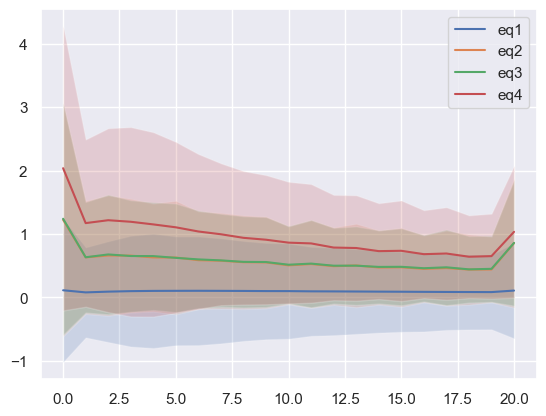

In [42]:
mean_resids, std_resids = losses.mean(axis=0), losses.std(axis=0)
std_resids /= mean_resids.mean(axis=1, keepdims=True)
for i in range(len(mean_resids)):
    plt.plot(mean_resids[i], label=f'eq{i+1}')
    plt.fill_between(np.arange(len(mean_resids[i])),
                     y1=mean_resids[i] - std_resids[i],
                     y2=mean_resids[i] + std_resids[i],
                     alpha=0.2)

plt.legend()
plt.show()

In [ ]:
x_momentum, y_momentum = [], []
for i in range(data.shape[-1] // num_channels):
    solution = data[..., i * num_channels: (i + 1) * num_channels]

    rho = solution[..., 0]
    ux, uy = solution[..., 1], solution[..., 2]

    total_x = np.sum(rho * ux, axis=(1, 2, 3))
    total_y = np.sum(rho * uy, axis=(1, 2, 3))
    
    x_momentum.append(total_x)
    y_momentum.append(total_y)

x_curves, y_curves = np.array(x_momentum), np.array(y_momentum)

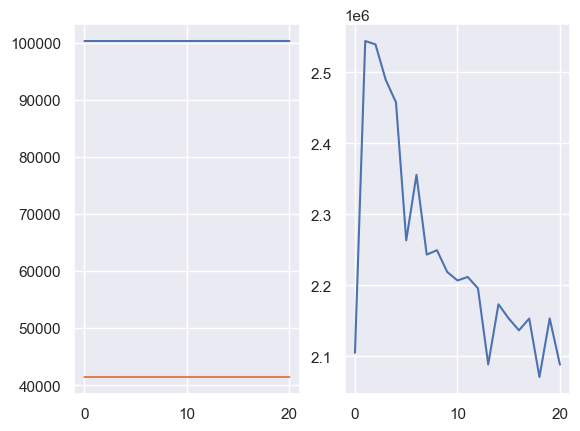

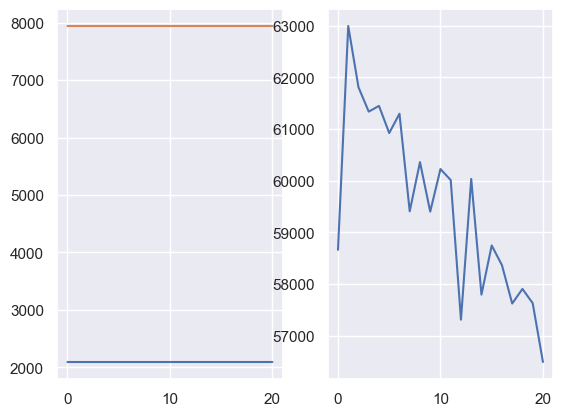

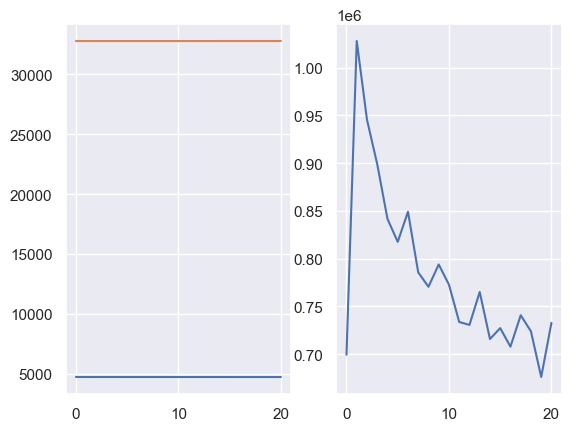

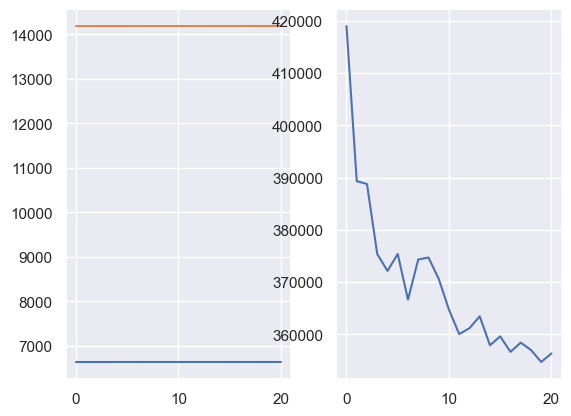

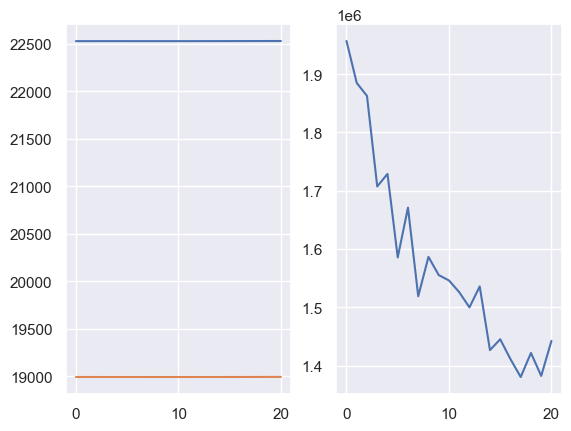

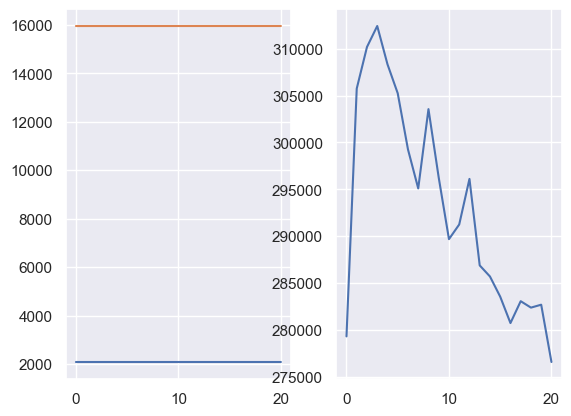

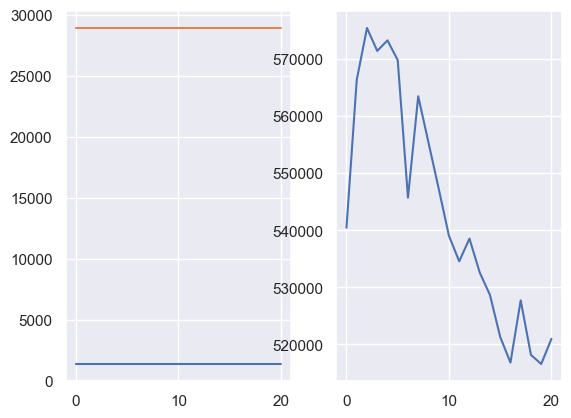

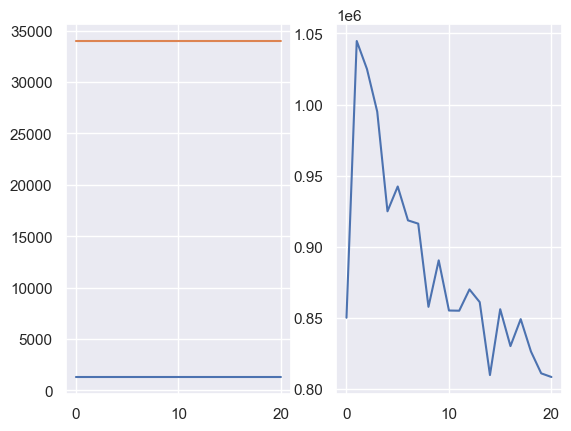

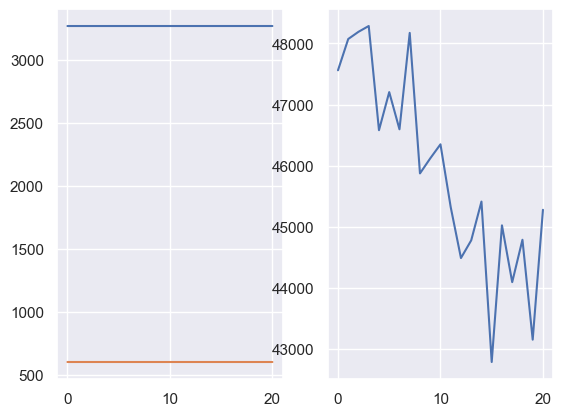

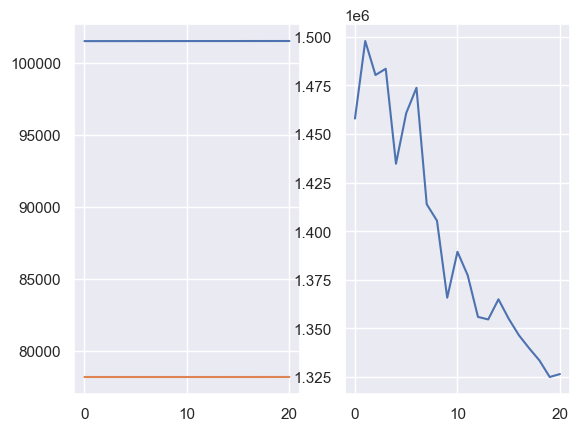

In [ ]:
for i in range(10):
    fig, (ax1, ax2) = plt.subplots(1, 2)
    xc, yc = abs(x_curves[i]), abs(y_curves[i])
    ec = energy_curves[i]

    ax1.plot(xc)
    ax1.plot(yc)
    ax2.plot(ec)

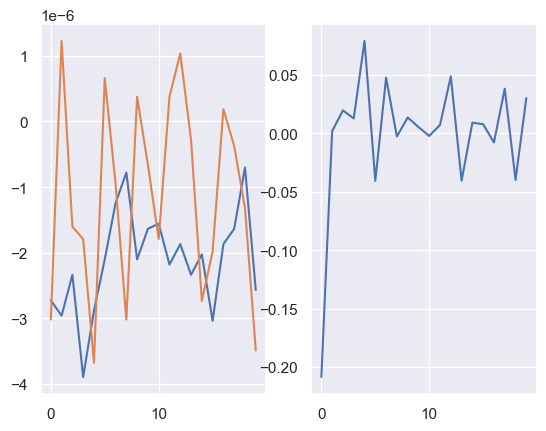

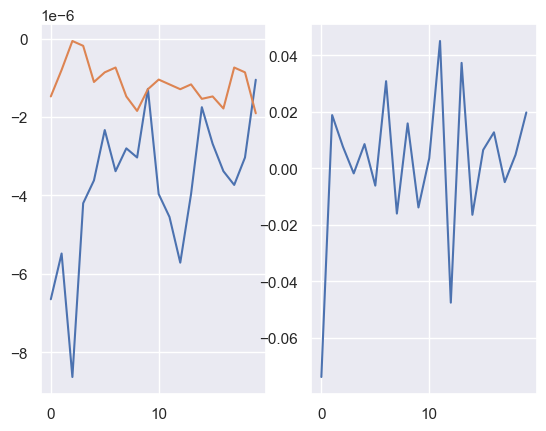

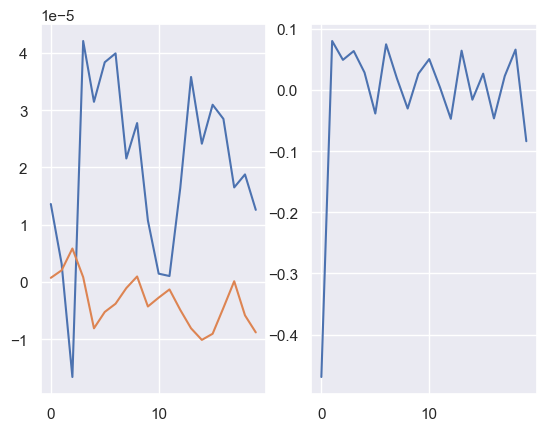

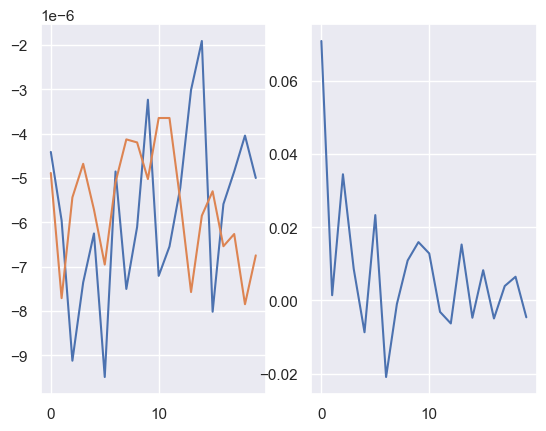

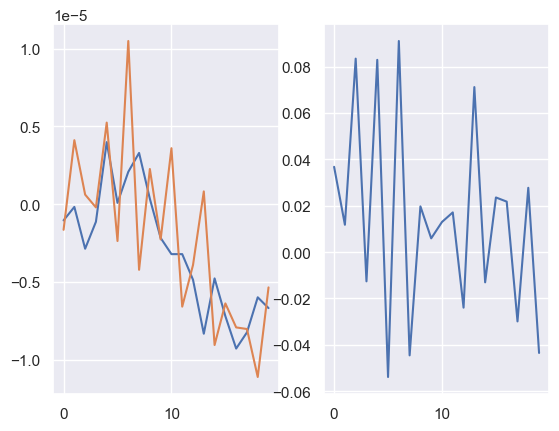

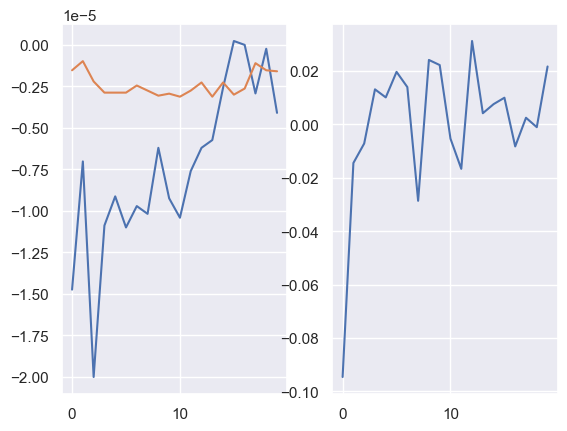

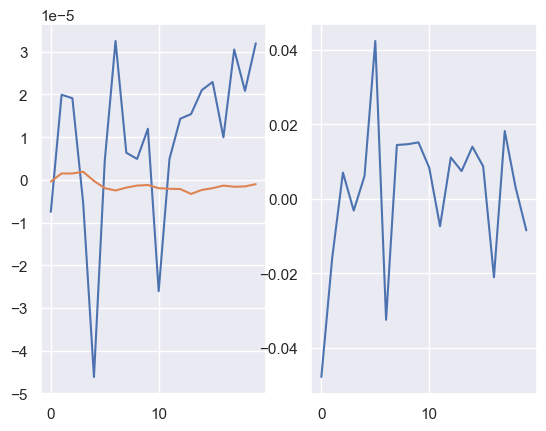

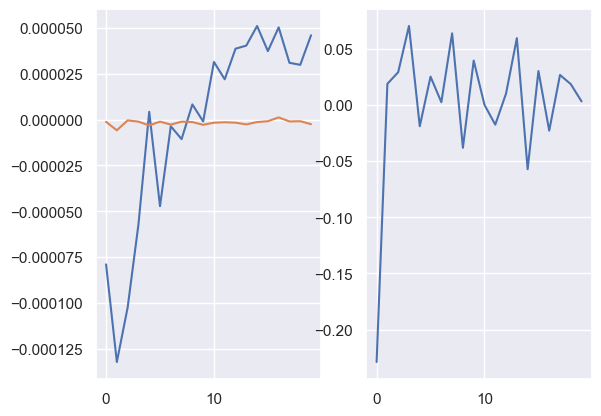

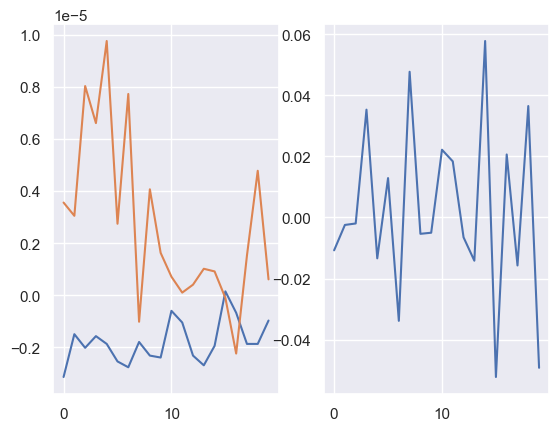

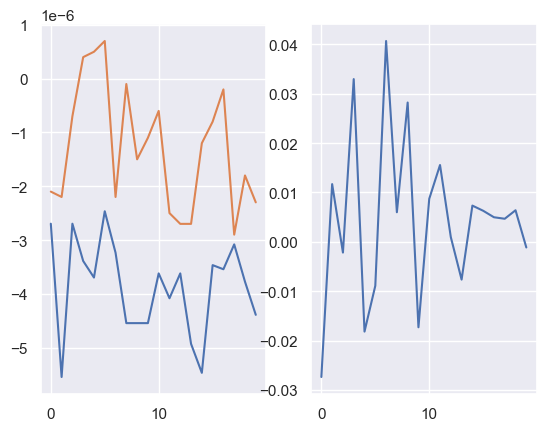

In [ ]:
for i in range(10):
    fig, (ax1, ax2) = plt.subplots(1, 2)
    xc = (abs(x_curves[i, :-1]) - abs(x_curves[i, 1:])) / abs(x_curves[i, :-1])
    yc = (abs(y_curves[i, :-1]) - abs(y_curves[i, 1:])) / abs(y_curves[i, :-1])
    ec = (energy_curves[i, :-1] - energy_curves[i, 1:]) / energy_curves[i, :-1]

    ax1.plot(xc)
    ax1.plot(yc)
    ax2.plot(ec)